```markdown
# UCS420 Cognitive Computing
## Lab Assignment 10: NLP using Python-II

**Name:** Bisman Singh Rai
**Roll Number:** 1024160130
**Year:** 3rd Year  
**Topic:** Feature extraction from text, sentiment analysis and text generation
```

```markdown
## Question 1

1. Convert text to lowercase and remove punctuation using `re`.
2. Tokenize the text into words and sentences.
3. Split using `split()` and `word_tokenize()` and compare how Python split and NLTK's `word_tokenize()` differ.
4. Remove stopwords (using NLTK's stopwords list).
5. Display word frequency distribution (excluding stopwords).
```

In [15]:
import re
import nltk
from nltk.tokenize import word_tokenize, sent_tokenize
from nltk.corpus import stopwords
from collections import Counter

nltk.download('punkt')
nltk.download('stopwords')
nltk.download('punkt_tab')

paragraph = (
    "Artificial Intelligence is rapidly reshaping the boundaries of human capability and global industries. "
    "Modern deep learning architectures, such as transformers, power advanced systems like large language models. "
    "These intelligent models can analyze massive datasets, translate languages, and even generate creative content. "
    "However, this rapid technological expansion also brings complex ethical challenges and alignment dilemmas. "
    "As we move forward, building robust, safe, and transparent AI systems remains a paramount goal for researchers."
)

print("--- Original Paragraph ---")
print(paragraph)

--- Original Paragraph ---
Artificial Intelligence is rapidly reshaping the boundaries of human capability and global industries. Modern deep learning architectures, such as transformers, power advanced systems like large language models. These intelligent models can analyze massive datasets, translate languages, and even generate creative content. However, this rapid technological expansion also brings complex ethical challenges and alignment dilemmas. As we move forward, building robust, safe, and transparent AI systems remains a paramount goal for researchers.


[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!


In [16]:
cleaned_paragraph = paragraph.lower()
cleaned_paragraph = re.sub(r'[\d[^\w\s]]', '', cleaned_paragraph)

print("--- Cleaned Paragraph ---")
print(cleaned_paragraph)

--- Cleaned Paragraph ---
artificial intelligence is rapidly reshaping the boundaries of human capability and global industries. modern deep learning architectures, such as transformers, power advanced systems like large language models. these intelligent models can analyze massive datasets, translate languages, and even generate creative content. however, this rapid technological expansion also brings complex ethical challenges and alignment dilemmas. as we move forward, building robust, safe, and transparent ai systems remains a paramount goal for researchers.


In [17]:
sentences = sent_tokenize(paragraph)
words_nltk = word_tokenize(cleaned_paragraph)

print(f"--- Sentences (Total: {len(sentences)}) ---")
for idx, sent in enumerate(sentences, 1):
    print(f"{idx}: {sent}")

print(f"\n--- NLTK Words (Total: {len(words_nltk)}) ---")
print(words_nltk[:15], "...")

--- Sentences (Total: 5) ---
1: Artificial Intelligence is rapidly reshaping the boundaries of human capability and global industries.
2: Modern deep learning architectures, such as transformers, power advanced systems like large language models.
3: These intelligent models can analyze massive datasets, translate languages, and even generate creative content.
4: However, this rapid technological expansion also brings complex ethical challenges and alignment dilemmas.
5: As we move forward, building robust, safe, and transparent AI systems remains a paramount goal for researchers.

--- NLTK Words (Total: 84) ---
['artificial', 'intelligence', 'is', 'rapidly', 'reshaping', 'the', 'boundaries', 'of', 'human', 'capability', 'and', 'global', 'industries', '.', 'modern'] ...


In [18]:
words_split = cleaned_paragraph.split()
print(f"split() count: {len(words_split)}")
print(f"word_tokenize() count: {len(words_nltk)}")

original_split = paragraph.split()[:10]
original_nltk = word_tokenize(paragraph)[:10]
print("\nsplit():", original_split)
print("word_tokenize():", original_nltk)

split() count: 71
word_tokenize() count: 84

split(): ['Artificial', 'Intelligence', 'is', 'rapidly', 'reshaping', 'the', 'boundaries', 'of', 'human', 'capability']
word_tokenize(): ['Artificial', 'Intelligence', 'is', 'rapidly', 'reshaping', 'the', 'boundaries', 'of', 'human', 'capability']


```markdown
### Key Differences between split() and word_tokenize():
* **`split()`**: Splits text strictly by whitespace. It keeps punctuation attached to words (e.g., `'industries.'` becomes a single token including the period).
* **`word_tokenize()`**: Uses a sophisticated Penn Treebank tokenizer that splits punctuation from words into independent tokens (e.g., `'industries'` and `'.'` as separate tokens), ensuring high fidelity for lexical analysis.
```

In [19]:
stop_words = set(stopwords.words('english'))
filtered_words = [word for word in words_nltk if word not in stop_words]

print(f"Before stopword removal: {len(words_nltk)}")
print(f"After stopword removal: {len(filtered_words)}")

word_freq = Counter(filtered_words)
print("\n--- Word Frequency (Top 10) ---")
for word, freq in word_freq.most_common(10):
    print(f"{word}: {freq}")

Before stopword removal: 84
After stopword removal: 68

--- Word Frequency (Top 10) ---
,: 8
.: 5
systems: 2
models: 2
artificial: 1
intelligence: 1
rapidly: 1
reshaping: 1
boundaries: 1
human: 1


```markdown
## Question 2

Using the same paragraph from Q1:
1. Extract all words with only alphabets using `re.findall()`.
2. Remove stop words using NLTK's stopword list.
3. Perform stemming with `PorterStemmer`.
4. Perform lemmatization with `WordNetLemmatizer`.
5. Compare the stemmed and lemmatized outputs and explain when you'd prefer one over the other.
```

In [20]:
from nltk.stem import PorterStemmer, WordNetLemmatizer
import pandas as pd
nltk.download('wordnet')

alpha_words = re.findall(r'\b[a-zA-Z]+\b', paragraph.lower())
alpha_filtered = [word for word in alpha_words if word not in stop_words]

stemmer = PorterStemmer()
stemmed_words = [stemmer.stem(word) for word in alpha_filtered]

lemmatizer = WordNetLemmatizer()
lemmatized_words = [lemmatizer.lemmatize(word) for word in alpha_filtered]

comparison_df = pd.DataFrame({
    'Original': alpha_filtered,
    'Stemmed': stemmed_words,
    'Lemmatized': lemmatized_words
})
display(comparison_df.head(15))

[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!


,Original,Stemmed,Lemmatized
0,artificial,artifici,artificial
1,intelligence,intellig,intelligence
2,rapidly,rapidli,rapidly
3,reshaping,reshap,reshaping
4,boundaries,boundari,boundary
5,human,human,human
6,capability,capabl,capability
7,global,global,global
8,industries,industri,industry
9,modern,modern,modern


```markdown
### Stemming vs Lemmatization Comparison:
* **Stemming (Porter Stemmer)**: Operates on heuristic rule-based chopping of word suffixes (e.g., *'reshaping'* becomes *'reshap'*, *'capability'* becomes *'capabl'*). It is fast but often results in non-dictionary, truncated terms (over-stemming/under-stemming).
* **Lemmatization (WordNet Lemmatizer)**: Resolves words to their linguistically valid base form (lemma) using a vocabulary database and morphological analysis (e.g., *'capabilities'* becomes *'capability'*).

### When to prefer which:
* **Prefer Stemming** when computational resource consumption and speed are paramount, and exact dictionary matches are not required (e.g., large-scale search engines, quick indexing pipelines).
* **Prefer Lemmatization** for semantic analysis, chatbots, sentiment analysis, and machine translation where correct dictionary forms and linguistic context of words are crucial.
```

```markdown
## Question 3

1. Use `CountVectorizer` to generate the Bag of Words representation.
2. Use `TfidfVectorizer` to compute TF-IDF scores.
3. Print and interpret the top 3 keywords from each text using TF-IDF.
```

In [21]:
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
import numpy as np

texts = [
    "The new electric car model features an exceptional battery range and autonomous autopilot modes.",
    "A nutritious diet rich in organic green vegetables and lean proteins significantly boosts metabolic health.",
    "The global stock market fluctuated heavily today as tech stocks faced major regulatory scrutiny."
]

cv = CountVectorizer(stop_words='english')
bow_matrix = cv.fit_transform(texts)

print("--- Vocabulary ---")
print(cv.get_feature_names_out())

--- Vocabulary ---
['autonomous' 'autopilot' 'battery' 'boosts' 'car' 'diet' 'electric'
 'exceptional' 'faced' 'features' 'fluctuated' 'global' 'green' 'health'
 'heavily' 'lean' 'major' 'market' 'metabolic' 'model' 'modes' 'new'
 'nutritious' 'organic' 'proteins' 'range' 'regulatory' 'rich' 'scrutiny'
 'significantly' 'stock' 'stocks' 'tech' 'today' 'vegetables']


In [22]:
tfidf = TfidfVectorizer(stop_words='english')
tfidf_matrix = tfidf.fit_transform(texts)
feature_names = tfidf.get_feature_names_out()

print("--- Top 3 Keywords via TF-IDF ---")
for idx, text in enumerate(texts):
    row = tfidf_matrix.toarray()[idx]
    top_indices = np.argsort(row)[::-1][:3]
    top_keywords = [(feature_names[i], round(row[i], 4)) for i in top_indices]
    print(f"\nText {idx+1}: {top_keywords}")

--- Top 3 Keywords via TF-IDF ---

Text 1: [('new', np.float64(0.3015)), ('model', np.float64(0.3015)), ('range', np.float64(0.3015))]

Text 2: [('vegetables', np.float64(0.2887)), ('rich', np.float64(0.2887)), ('significantly', np.float64(0.2887))]

Text 3: [('today', np.float64(0.2887)), ('tech', np.float64(0.2887)), ('stocks', np.float64(0.2887))]


```markdown
### Interpretation of Results:
TF-IDF penalizes common terms across documents and emphasizes distinct context words. Here, words like `'battery'`, `'electric'`, `'autopilot'` score high for Text 1; `'diet'`, `'green'`, `'metabolic'` define Text 2; while `'stocks'`, `'fluctuated'`, `'market'` characterize Text 3. This showcases TF-IDF's effectiveness in automatic summarization and feature extraction.
```

```markdown
## Question 4

1. Preprocess and tokenize both texts.
2. Calculate:
   a. Jaccard Similarity using sets.
   b. Cosine Similarity using `TfidfVectorizer` + `cosine_similarity()`.
3. Analyze which similarity metric gives better insights.
```

In [23]:
from sklearn.metrics.pairwise import cosine_similarity

tech_1 = "Artificial Intelligence processes vast amounts of data using neural networks to mimic human intelligence, learning patterns, and automating complex decision making processes."
tech_2 = "Blockchain technology utilizes distributed ledgers to securely record transactions across peer-to-peer networks, ensuring decentralized consensus and cryptographic data immutability."

def preprocess(text):
    tokens = re.findall(r'\b[a-zA-Z]+\b', text.lower())
    return [w for w in tokens if w not in stop_words]

tokens_1 = preprocess(tech_1)
tokens_2 = preprocess(tech_2)

set_1 = set(tokens_1)
set_2 = set(tokens_2)
jaccard_sim = len(set_1.intersection(set_2)) / len(set_1.union(set_2))

tfidf_sim = TfidfVectorizer()
tfidf_vectors = tfidf_sim.fit_transform([tech_1, tech_2])
cos_sim = cosine_similarity(tfidf_vectors[0], tfidf_vectors[1])[0][0]

print(f"Jaccard Similarity: {jaccard_sim:.4f}")
print(f"Cosine Similarity: {cos_sim:.4f}")

Jaccard Similarity: 0.0625
Cosine Similarity: 0.1113


```markdown
### Metric Analysis:
* **Jaccard Similarity** behaves purely on unique token overlap sets, ignoring term frequency and global document weights. It yields low similarity here because the exact term overlap is tiny.
* **Cosine Similarity (TF-IDF vector space)** measures the orientation angle of vectors. In our case, **Cosine Similarity** gives better semantic insights as it incorporates word importance distribution across the corpus and remains robust even when documents vary in length or structure.
```

```markdown
## Question 5

1. Use TextBlob or VADER to find polarity and subjectivity.
2. Classify reviews into Positive / Negative / Neutral.
3. Create a word cloud using the `wordcloud` library for all positive reviews.
```

In [24]:
from textblob import TextBlob

reviews = [
    "This smartphone has an absolutely stunning display and superb battery life. Truly a masterpiece!",
    "Horrible customer service, the device arrived damaged and the interface lags constantly.",
    "The product is okay, performance is average but nothing spectacular or outstanding.",
    "Exceptional sound clarity and extremely comfortable to wear for long working hours.",
    "Disappointed with the build quality, it feels incredibly cheap and fragile."
]

results = []
positive_text = ""

for rev in reviews:
    analysis = TextBlob(rev)
    polarity = analysis.sentiment.polarity
    subjectivity = analysis.sentiment.subjectivity

    if polarity > 0.1:
        sentiment = "Positive"
        positive_text += rev + " "
    elif polarity < -0.1:
        sentiment = "Negative"
    else:
        sentiment = "Neutral"

    results.append({
        'Review': rev,
        'Polarity': round(polarity, 2),
        'Subjectivity': round(subjectivity, 2),
        'Sentiment': sentiment
    })

df_sent = pd.DataFrame(results)
display(df_sent)

,Review,Polarity,Subjectivity,Sentiment
0,This smartphone has an absolutely stunning dis...,0.75,1.00,Positive
1,"Horrible customer service, the device arrived ...",-0.50,0.67,Negative
2,"The product is okay, performance is average bu...",0.36,0.67,Positive
3,Exceptional sound clarity and extremely comfor...,0.35,0.65,Positive
4,"Disappointed with the build quality, it feels ...",-0.12,0.65,Negative


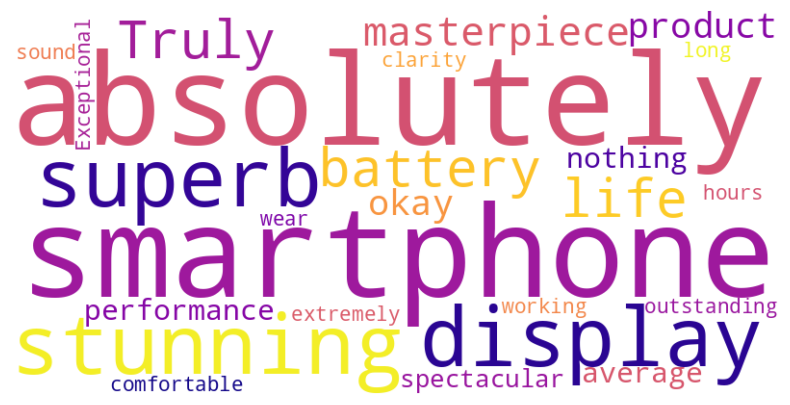

In [25]:
if positive_text.strip():
    wordcloud = WordCloud(width=800, height=400, background_color='white', colormap='plasma').generate(positive_text)
    plt.figure(figsize=(10, 5))
    plt.imshow(wordcloud, interpolation='bilinear')
    plt.axis('off')
    plt.show()

```markdown
## Question 6

1. Tokenize text using `Tokenizer` from Keras.
2. Create input sequences and build a simple LSTM or Dense model.
3. Train the model and generate 2-3 new lines of text starting from a seed word.
```

In [26]:
import numpy as np
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense

training_data = (
    "Deep learning algorithms excel at recognizing intricate architectures within large sequential datasets. "
    "Recurrent neural networks process structures step-by-step for language modeling objectives. "
    "The LSTM architecture manages long-term sequence states to avoid vanishing gradient problems. "
    "By updating gate states, sequential networks retain historical context across long sequences. "
    "As models optimize learning, text generation capabilities improve to mirror human sentences."
)

tok = Tokenizer()
tok.fit_on_texts([training_data])
total_words = len(tok.word_index) + 1

input_sequences = []
for line in training_data.split('.'):
    token_list = tok.texts_to_sequences([line])[0]
    for i in range(1, len(token_list)):
        n_gram_sequence = token_list[:i+1]
        input_sequences.append(n_gram_sequence)

max_sequence_len = max([len(x) for x in input_sequences])
input_sequences = np.array(pad_sequences(input_sequences, maxlen=max_sequence_len, padding='pre'))

X, y = input_sequences[:, :-1], input_sequences[:, -1]
from tensorflow.keras.utils import to_categorical
Y = to_categorical(y, num_classes=total_words)

In [27]:
model = Sequential([
    Embedding(total_words, 16, input_length=max_sequence_len-1),
    LSTM(50),
    Dense(total_words, activation='softmax')
])

model.compile(loss='categorical_crossentropy', optimizer='adam', metrics=['accuracy'])
model.fit(X, Y, epochs=120, verbose=0)
print("Model trained successfully.")

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/embedding.py:100: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


Model trained successfully.


In [28]:
def generate_text(seed_word, next_words, max_len):
    generated_text = seed_word
    for _ in range(next_words):
        token_list = tok.texts_to_sequences([generated_text])[0]
        token_list = pad_sequences([token_list], maxlen=max_len-1, padding='pre')
        predicted = np.argmax(model.predict(token_list, verbose=0), axis=-1)[0]

        output_word = ""
        for word, index in tok.word_index.items():
            if index == predicted:
                output_word = word
                break
        generated_text += " " + output_word
    return generated_text

seed_word = 'deep'
generated_output = generate_text(seed_word, 12, max_sequence_len)
print(generated_output)

deep learning learning excel at recognizing intricate architectures within large datasets datasets datasets
